# Medical Insurance Cleaned Dataset — Data Visualization

Visualizing `insurance_cleaned.csv` using `matplotlib` to explore patterns and identify the most important features affecting medical insurance `charges`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data_cleaning/insurance_cleaned.csv")
print("Shape:", df.shape)
df.head()

Shape: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Distribution of Medical Charges
Most policyholders have charges below \$15,000, while a smaller group extends up to \$63,770 (right-skewed distribution).

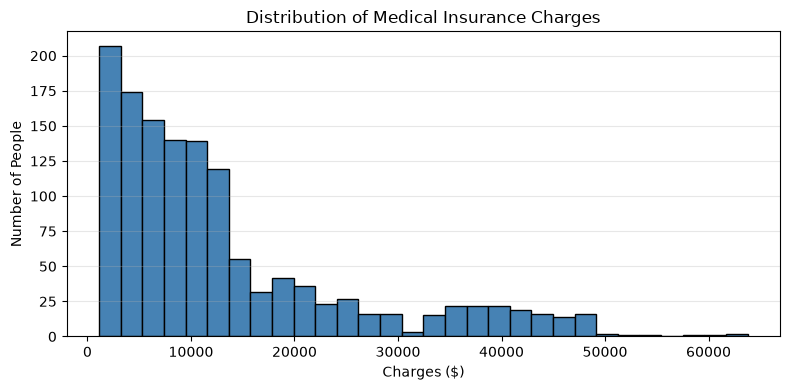

In [2]:
plt.figure(figsize=(8, 4))
plt.hist(df["charges"], bins=30, color="steelblue", edgecolor="black")
plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Charges ($)")
plt.ylabel("Number of People")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Smoking Status vs. Charges (Most Important Feature)
- **Smokers** (`274` people) have an average charge of **\$32,050** (median **\$34,456**).
- **Non-smokers** (`1,063` people) have an average charge of **\$8,441** (median **\$7,346**).
- Smoking is the strongest single driver of higher insurance costs (~3.8x higher mean).

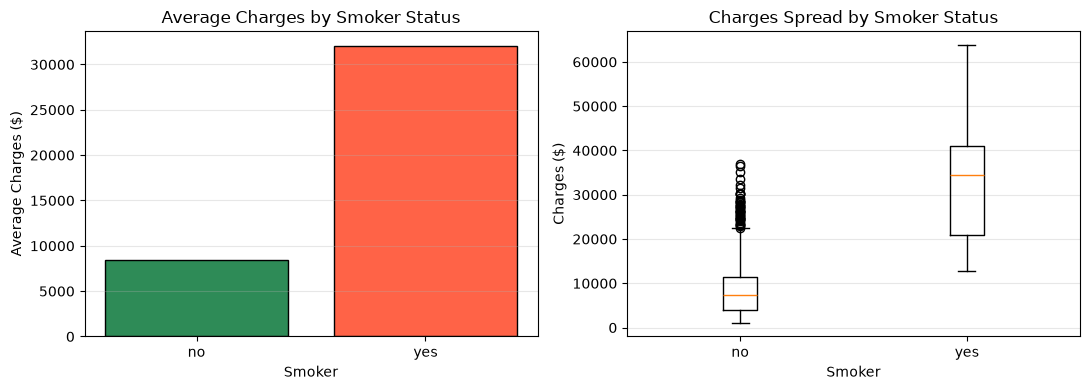

In [3]:
smoker_means = df.groupby("smoker")["charges"].mean()
non_smoker_charges = df[df["smoker"] == "no"]["charges"]
smoker_charges = df[df["smoker"] == "yes"]["charges"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(smoker_means.index, smoker_means.values, color=["seagreen", "tomato"], edgecolor="black")
axes[0].set_title("Average Charges by Smoker Status")
axes[0].set_xlabel("Smoker")
axes[0].set_ylabel("Average Charges ($)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].boxplot([non_smoker_charges, smoker_charges], tick_labels=["no", "yes"])
axes[1].set_title("Charges Spread by Smoker Status")
axes[1].set_xlabel("Smoker")
axes[1].set_ylabel("Charges ($)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Age vs. Charges (Important Numeric Feature)
- Charges steadily increase with **age** (overall correlation `0.30`).
- Splitting by `smoker` reveals clear parallel bands: older smokers face the highest baseline charges.

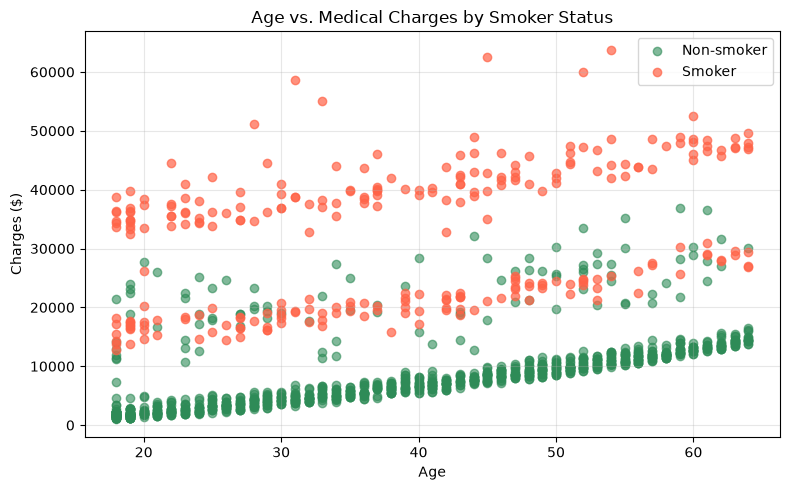

In [4]:
smokers = df[df["smoker"] == "yes"]
non_smokers = df[df["smoker"] == "no"]

plt.figure(figsize=(8, 5))
plt.scatter(non_smokers["age"], non_smokers["charges"], alpha=0.6, color="seagreen", label="Non-smoker")
plt.scatter(smokers["age"], smokers["charges"], alpha=0.7, color="tomato", label="Smoker")
plt.title("Age vs. Medical Charges by Smoker Status")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. BMI vs. Charges (Strong Interaction with Smoking)
- Overall correlation between `bmi` and `charges` is `0.20`, but the scatter plot shows a sharp threshold around **BMI = 30** for smokers:
  - Smokers with `bmi < 30`: mean **\$21,363**
  - Smokers with `bmi >= 30`: mean **\$41,558** (nearly double)
  - Non-smokers stay relatively flat across BMI (**\$7,977** for `bmi < 30` vs. **\$8,856** for `bmi >= 30`).

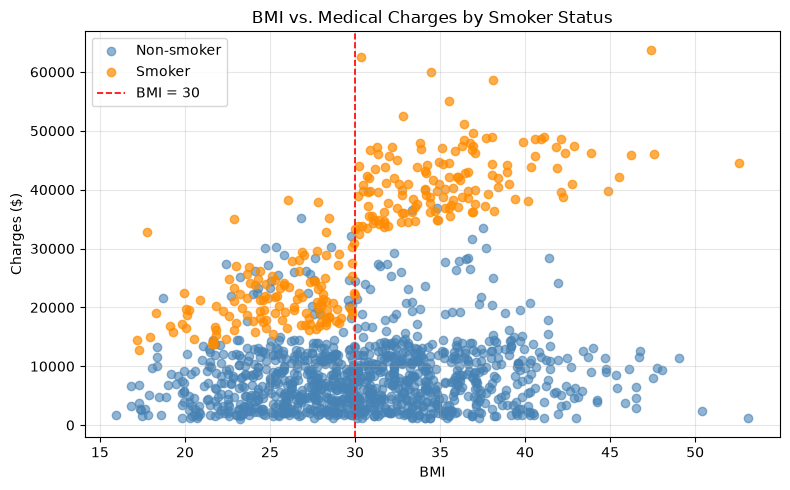

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(non_smokers["bmi"], non_smokers["charges"], alpha=0.6, color="steelblue", label="Non-smoker")
plt.scatter(smokers["bmi"], smokers["charges"], alpha=0.7, color="darkorange", label="Smoker")
plt.axvline(30, color="red", linestyle="--", linewidth=1.2, label="BMI = 30")
plt.title("BMI vs. Medical Charges by Smoker Status")
plt.xlabel("BMI")
plt.ylabel("Charges ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Charges by Region, Sex, and Number of Children (Secondary Features)
- **Region**: `southeast` has the highest average charges (**\$14,735**), compared to `northeast` (**\$13,406**), `northwest` (**\$12,451**), and `southwest` (**\$12,347**).
- **Sex**: Males have a slightly higher mean (**\$13,975**) than females (**\$12,570**), though median charges are nearly equal (**\$9,378** vs. **\$9,413**).
- **Children**: Weak correlation (`0.07`); average charges rise modestly from 0 to 3 children (**\$12,385** to **\$15,355**), while 4–5 children have small sample counts (`25` and `18` rows).

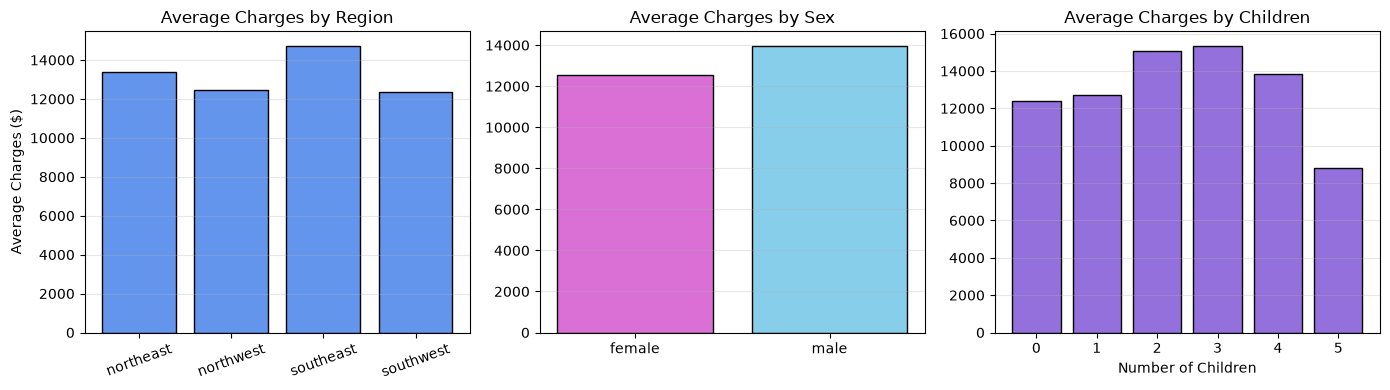

In [9]:
region_means = df.groupby("region")["charges"].mean()
sex_means = df.groupby("sex")["charges"].mean()
children_means = df.groupby("children")["charges"].mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].bar(region_means.index, region_means.values, color="cornflowerblue", edgecolor="black")
axes[0].set_title("Average Charges by Region")
axes[0].set_ylabel("Average Charges ($)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(sex_means.index, sex_means.values, color=["orchid", "skyblue"], edgecolor="black")
axes[1].set_title("Average Charges by Sex")
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(children_means.index.astype(str), children_means.values, color="mediumpurple", edgecolor="black")
axes[2].set_title("Average Charges by Children")
axes[2].set_xlabel("Number of Children")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Numeric Correlation Matrix
Among numeric features, `age` (`0.30`) and `bmi` (`0.20`) correlate positively with `charges`, while `children` (`0.07`) has minimal linear correlation.

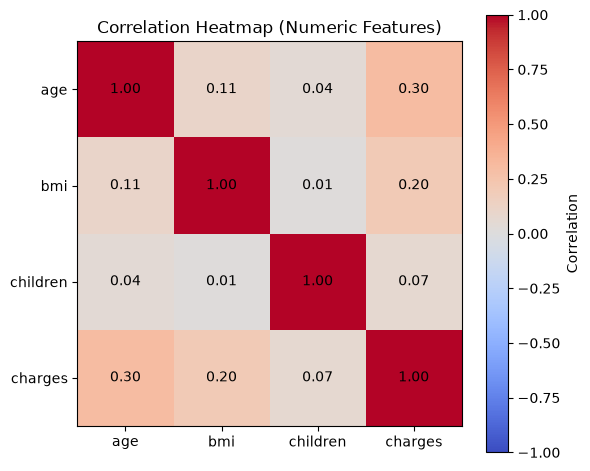

In [7]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns)
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")

plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

## Summary of Important Features Found

| Feature / Interaction | Importance | Key Observation from `insurance_cleaned.csv` |
| --- | --- | --- |
| `smoker` | **Very High (Primary Driver)** | Smokers (`274` rows) average **\$32,050** (median **\$34,456**) vs. **\$8,441** (median **\$7,346**) for non-smokers (`1,063` rows) ? ~3.8x higher mean. |
| `bmi` + `smoker` | **High (Risk Interaction)** | Smokers with `bmi >= 30` average **\$41,558** vs. **\$21,363** for smokers with `bmi < 30`; non-smokers stay relatively flat (**\$7,977**?**\$8,856**). |
| `age` | **High (Strongest Numeric)** | Positive correlation (`r = 0.30`) with `charges`; costs rise steadily with age in clear parallel bands for smokers and non-smokers. |
| `bmi` | **Moderate** | Overall correlation (`r = 0.20`) with `charges`, driven largely by the sharp jump among obese smokers (`bmi >= 30`). |
| `region` | **Low** | `southeast` has the highest average (**\$14,735**), followed by `northeast` (**\$13,406**), `northwest` (**\$12,451**), and `southwest` (**\$12,347**). |
| `sex` | **Low** | Males average slightly higher (**\$13,975** vs. **\$12,570** for females), though medians are nearly identical (**\$9,378** vs. **\$9,413**). |
| `children` | **Very Low** | Minimal linear correlation (`r = 0.07`); slight rise from `0` to `3` children (**\$12,385** to **\$15,355**), with small sample sizes at `4`?`5`. |